# Tugas 2 — Pendekatan Non-Deep Learning: Inspeksi Kemasan Kubus Gingerbread 3D

Notebook ini mendokumentasikan alur kerja Non-Deep Learning yang **kami** bangun untuk memprediksi jumlah total gingerbread, jumlah cacat, serta jumlah desain unik pada tiga sisi kemasan kubus (`front`, `right`, `top`). Selain pipeline utama berbasis Multi-Template Coarse-to-Fine NCC, **kami** turut mengevaluasi tiga model pembanding (`SIFT + RANSAC`, `ORB + RANSAC`, dan `Contour + HSV`) yang berbagi front-end geometri identik dan mengekspor berkas submisi CSV terpisah.

### 1. Inisialisasi Lingkungan, Referensi `template_all`, dan Dataset
Kami menyiapkan jalur modul `src.task2_non_dl`, memuat keempat predictor Non-Deep Learning beserta utilitas evaluasinya, lalu mengekstrak kamus 7 desain referensi lengkap (`template_all/`) dan indeks anotasi `100` citra kubus berlabel dari arsip pelatihan.

In [1]:
import hashlib
import io
import json
import sys
import time
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "task2_non_dl").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.task2_non_dl import (
    CANONICAL_FACE_SIZE,
    align_and_score_cookie,
    compute_vanishing_center,
    extract_cube_hexagon,
    fit_background_model,
    predict_cube_contour_hsv,
    predict_cube_non_dl,
    predict_cube_orb_ransac,
    predict_cube_sift_ransac,
    prepare_reference_cache,
    rectify_face,
    segment_cube_faces,
    segment_face_cookies,
)
from src.task2_non_dl.baselines import (
    _build_feature_config,
    _extract_contour_zone_stats,
    _prepare_contour_hsv_refs,
    _prepare_feature_refs,
    _score_contour_hsv_cookie,
    _umeyama_2d_similarity,
)
from src.task2_non_dl.detector import (
    _extract_aligned_design_stats,
    _fit_shading_affine,
    _major_axis_angle_deg,
    _match_template_coarse,
    _match_template_fine,
    _rotate_crop_patch,
)
from src.task2_non_dl.evaluate_and_visualize import (
    FACES,
    cube_columns,
    evaluate_cube_dataframe,
    load_zip_references,
    validate_cube_predictions,
)

TRAIN_ZIP = ROOT / "data" / "gingerbread_seed2026_students_training.zip"
HIDDEN_ZIP = ROOT / "data" / "hidden_students.zip"

with zipfile.ZipFile(TRAIN_ZIP) as zf:
    references = load_zip_references(zf)
    annotations = json.loads(zf.read("cube_annotations.json"))

print(f"Total citra kubus berlabel: {len(annotations)}")
print(f"Referensi desain tersedia : {[(k, v['name'], v['rgba'].shape) for k, v in references.items()]}")

Total citra kubus berlabel: 100
Referensi desain tersedia : [(1, 'blue_wizard', (512, 256, 4)), (2, 'brown_hat_gnome', (512, 256, 4)), (3, 'green_hat_elf', (512, 256, 4)), (4, 'pilgrim', (512, 256, 4)), (5, 'santa', (512, 256, 4)), (6, 'striped_hat_elf', (512, 256, 4)), (7, 'witch', (512, 256, 4))]


### 2. Rekonstruksi Geometri 3D Kubus dan Rektifikasi Perspektif
Kami memodelkan iluminasi latar belakang memakai regresi kuadratik-radial $B(u,v) = c_0 + c_1 u + c_2 v + c_3 (u^2 + v^2)$ per kanal RGB dengan *inlier re-fit* dua tahap agar gradasi bayangan tersingkirkan. Selanjutnya, kami mengekstraksi 6 sudut terluar kubus pada presisi sub-piksel lewat perpotongan garis Huber (`cv2.fitLine`), mencari titik temu tiga rusuk dalam (`v_center`) melalui proyeksi vanishing point homogen beserta disambiguasi paritas kuadran, lalu meluruskan sisi `front`, `right`, dan `top` ke bidang kanonik `384x384` via transformasi homography.

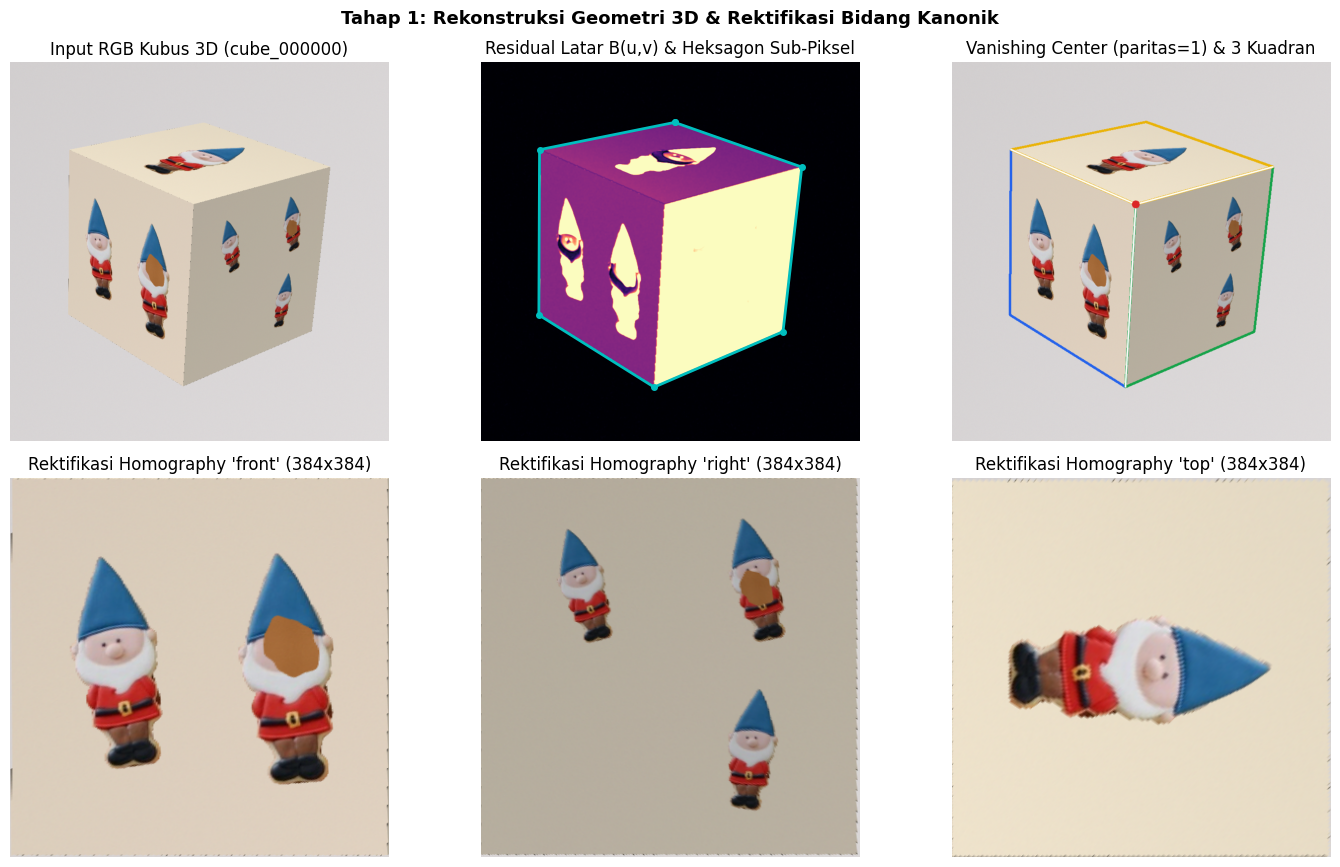

In [2]:
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    sample_ann = annotations[0]
    with Image.open(io.BytesIO(zf.read(sample_ann["image"]))) as im:
        sample_rgb = np.asarray(im.convert("RGB"))

bg_model, dist_map = fit_background_model(sample_rgb)
hex_pts, fg_mask = extract_cube_hexagon(sample_rgb, dist_map=dist_map)
v_center, parity = compute_vanishing_center(hex_pts, rgb=sample_rgb)
face_quads = segment_cube_faces(sample_rgb, hex_pts, v_center, parity=parity)
warped_faces = {fn: rectify_face(sample_rgb, face_quads[fn], CANONICAL_FACE_SIZE)[0] for fn in FACES}

fig, axes = plt.subplots(2, 3, figsize=(14.5, 8.8))
axes[0, 0].imshow(sample_rgb)
axes[0, 0].set_title(f"Input RGB Kubus 3D ({Path(sample_ann['image']).stem})")

axes[0, 1].imshow(dist_map, cmap="magma", vmin=0, vmax=65)
axes[0, 1].plot(np.r_[hex_pts[:, 0], hex_pts[0, 0]], np.r_[hex_pts[:, 1], hex_pts[0, 1]], "c-o", lw=2, ms=4)
axes[0, 1].set_title("Residual Latar B(u,v) & Heksagon Sub-Piksel")

overlay_q = sample_rgb.copy()
face_cols = {"front": (37, 99, 235), "right": (22, 163, 74), "top": (234, 179, 8)}
for fn in FACES:
    cv2.polylines(overlay_q, [np.round(face_quads[fn]).astype(np.int32)], True, face_cols[fn], 4)
for idx_v in range(parity, 6, 2):
    p_end = tuple(np.round(hex_pts[idx_v]).astype(int))
    p_vc = tuple(np.round(v_center).astype(int))
    cv2.line(overlay_q, p_vc, p_end, (255, 255, 255), 2, cv2.LINE_AA)
cv2.circle(overlay_q, tuple(np.round(v_center).astype(int)), 8, (220, 38, 38), -1)
axes[0, 2].imshow(overlay_q)
axes[0, 2].set_title(f"Vanishing Center (paritas={parity}) & 3 Kuadran")

for idx_f, fn in enumerate(FACES):
    axes[1, idx_f].imshow(warped_faces[fn])
    axes[1, idx_f].set_title(f"Rektifikasi Homography '{fn}' (384x384)")

for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Tahap 1: Rekonstruksi Geometri 3D & Rektifikasi Bidang Kanonik", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 3. Segmentasi Cookie, Penggabungan Fragmen, & Multi-Template Scoring (`Main NCC`)
Pada setiap sisi kanonik `384x384`, kami mengestimasi warna kardus dominan melalui median area interior, menyegmentasi cookie memakai jarak Euclidean terhadap median kardus, menolak artefak strip tepi rusuk, serta menyatukan kembali fragmen cookie miring yang terbelah oleh lubang memakai rasio aspek terorientasi (`cv2.minAreaRect`). Setiap instansi kemudian kami sejajarkan secara *coarse-to-fine* (`TM_CCOEFF_NORMED` `0.35x` menuju jendela *fine* ber-mask) terhadap ketujuh desain dan kami nilai dengan skor gabungan `design_score`.

In [3]:
ref_cache = prepare_reference_cache(references)
ref0 = next(iter(ref_cache.values()))

for fn in FACES:
    w_face = warped_faces[fn]
    comps, card_med = segment_face_cookies(w_face)
    peer = (
        float(np.median([max(c["bbox"][2] / ref0["w"], c["bbox"][3] / ref0["h"]) for c in comps]))
        if len(comps) >= 2
        else None
    )
    print(f"Sisi {fn:5s} -> terdeteksi {len(comps)} cookie (median warna kardus={np.round(card_med, 1).tolist()}):")
    for idx_c, comp in enumerate(comps, start=1):
        sc = align_and_score_cookie(w_face, comp, ref_cache, card_med, peer_scale=peer)
        status = "CACAT" if sc["is_defective"] else "SEMPURNA"
        print(
            f"  Cookie #{idx_c} bbox={comp['bbox']} | ncc={sc['ncc']:.3f} | "
            f"miss={sc['miss_sil']:.3f}, hole={sc['hole_frac']:.3f}, blob={sc['blob_frac']:.3f} "
            f"-> ratio={sc['defect_ratio']:.2f} ({status})"
        )

Sisi front -> terdeteksi 2 cookie (median warna kardus=[219.0, 205.0, 188.0]):


  Cookie #1 bbox=(61, 79, 94, 216) | ncc=0.942 | miss=0.000, hole=0.001, blob=0.029 -> ratio=0.34 (SEMPURNA)


  Cookie #2 bbox=(231, 76, 97, 235) | ncc=0.830 | miss=0.000, hole=0.002, blob=0.492 -> ratio=5.78 (CACAT)
Sisi right -> terdeteksi 3 cookie (median warna kardus=[182.0, 174.0, 159.0]):


  Cookie #1 bbox=(252, 41, 57, 126) | ncc=0.777 | miss=0.001, hole=0.016, blob=0.444 -> ratio=5.22 (CACAT)


  Cookie #2 bbox=(77, 52, 57, 115) | ncc=0.961 | miss=0.000, hole=0.001, blob=0.000 -> ratio=0.01 (SEMPURNA)


  Cookie #3 bbox=(250, 214, 51, 123) | ncc=0.977 | miss=0.001, hole=0.000, blob=0.000 -> ratio=0.01 (SEMPURNA)
Sisi top   -> terdeteksi 1 cookie (median warna kardus=[232.0, 221.0, 198.0]):


  Cookie #1 bbox=(56, 139, 268, 111) | ncc=0.991 | miss=0.000, hole=0.000, blob=0.000 -> ratio=0.00 (SEMPURNA)


#### Anatomi Matematis Evaluasi Cacat Tri-Modal (`Main NCC`)
Untuk memvisualisasikan cara kerja inspeksi piksel-ke-piksel setelah template disejajarkan, kami mencocokkan pencahayaan referensi $T$ terhadap observasi $O$ memakai regresi affine kokoh per kanal RGB ($\hat{T} = g \cdot T + b$) lalu menghitung peta residu toleran-geser $3 \times 3$:
$$R_{\text{shift}}(x, y) = \min_{\Delta x, \Delta y \in \{-1,0,1\}} \left\| O(x, y) - \hat{T}(x + \Delta x, y + \Delta y) \right\|_2$$
Dari peta tersebut, kami memisahkan tiga mode cacat secara ortogonal: `miss_sil` (`boundary_cut`, biru), `hole_inside` (`interior_hole`, kuning), dan `blob_err` (`missing_feature`, merah), lalu menetapkan status cacat jika $\max(\text{miss}/0.085,\ \text{hole}/0.055,\ \text{blob}/0.085) > 1.0$.

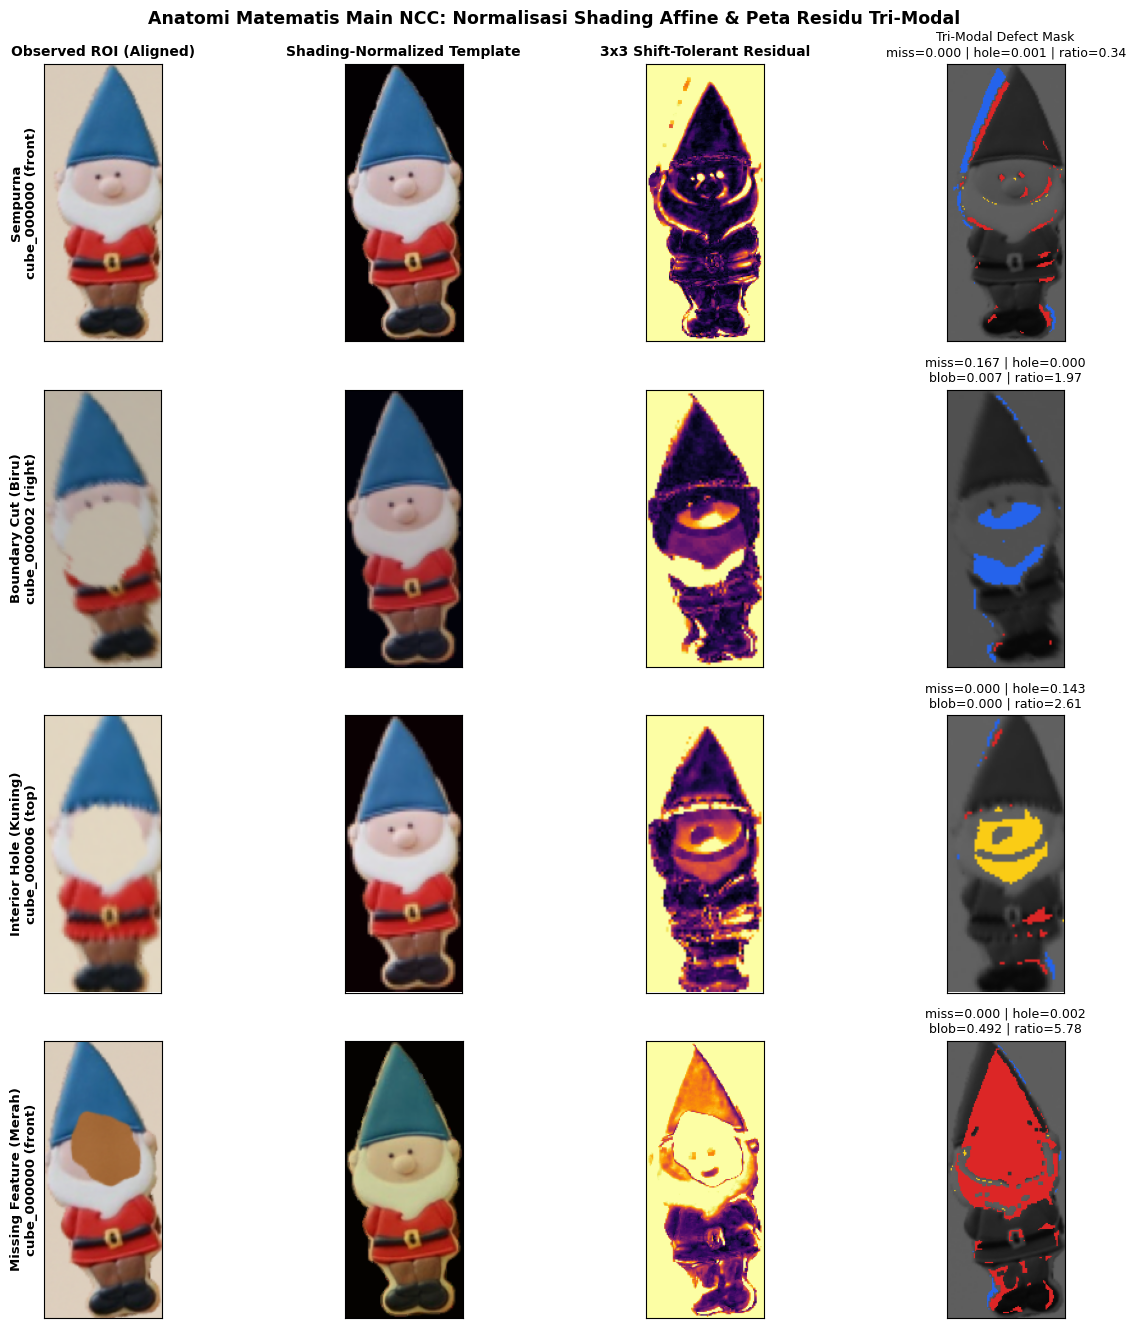

In [4]:
def inspect_aligned_cookie_maps(warped_face, comp, ref_cache, card_med, peer_scale=None):
    sc_out = align_and_score_cookie(warped_face, comp, ref_cache, card_med, peer_scale=peer_scale)
    r_entry = ref_cache[sc_out["design_id"]]
    theta, ar = _major_axis_angle_deg(comp["mask_solid"])
    base_angles = [theta, theta + 180.0] + ([0.0, 90.0, 180.0, -90.0] if ar < 1.48 else [])
    best_cand = None
    for ba in base_angles:
        for da in (-9.0, 0.0, 9.0):
            ang = ((ba + da + 180.0) % 360.0) - 180.0
            rc = _rotate_crop_patch(warped_face, comp, ang, card_med)
            if rc is None:
                continue
            rot_img, _, _, bbox = rc
            est_s = max(bbox[2] / max(1.0, float(r_entry["w"])), bbox[3] / max(1.0, float(r_entry["h"])))
            scales = [0.92 * est_s, est_s, 1.10 * est_s] + ([peer_scale] if peer_scale is not None else [])
            for sc_val in scales:
                sc_c = float(np.clip(sc_val, 0.25, 1.40))
                ch = _match_template_coarse(rot_img, bbox, r_entry, sc_c, card_med, coarse_factor=0.35)
                if ch is None:
                    continue
                fh = _match_template_fine(rot_img, r_entry, sc_c, (ch[1], ch[2]), card_med, search_rad=8)
                if fh is not None and (best_cand is None or fh[0] > best_cand["ncc"]):
                    best_cand = {"did": sc_out["design_id"], "ncc": fh[0], "ang": ang, "sc": sc_c, "gx": fh[1], "gy": fh[2], "rc": rc}
    st = _extract_aligned_design_stats(best_cand, r_entry, card_med)
    obs, tmpl_rgb, tmpl_m = st["obs_crop"], st["tmpl_rgb"], st["tmpl_mask"]
    solid_b, raw_b, solid_c = st["solid_bool"], st["raw_bool"], st["solid_crop"]
    intact = tmpl_m & raw_b
    gains, biases = _fit_shading_affine(obs[intact], tmpl_rgb[intact])
    norm_t = tmpl_rgb * gains + biases
    th, tw = st["th"], st["tw"]
    pad_nt = np.pad(norm_t, ((1, 1), (1, 1), (0, 0)), mode="edge")
    rsh = np.full((th, tw), 1e6, dtype=np.float32)
    for sy in range(3):
        for sx in range(3):
            rsh = np.minimum(rsh, np.linalg.norm(obs - pad_nt[sy : sy + th, sx : sx + tw], axis=2))

    miss_m = tmpl_m & ~solid_b & (rsh > 19.0)
    solid_er = cv2.erode(solid_c, np.ones((3, 3), np.uint8), iterations=1) > 0
    if comp.get("was_split", False):
        cnts_s, _ = cv2.findContours(solid_c, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        hm = np.zeros_like(solid_c)
        if cnts_s:
            cv2.drawContours(hm, [cv2.convexHull(np.vstack(cnts_s))], -1, 1, thickness=-1)
        hole_reg = solid_er | (cv2.erode(hm, np.ones((5, 5), np.uint8), iterations=1) > 0)
    else:
        hole_reg = solid_er
    hole_m = hole_reg & (np.linalg.norm(obs - card_med, axis=2) < 15.0) & (rsh > 19.0)
    blob_m = cv2.erode((intact & (rsh > 18.0)).astype(np.uint8), np.ones((3, 3), np.uint8), iterations=1) > 0

    gray_bg = np.repeat(cv2.cvtColor(np.clip(obs, 0, 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)[:, :, None], 3, axis=2)
    mask_vis = (0.45 * gray_bg).astype(np.uint8)
    mask_vis[miss_m] = (37, 99, 235)
    mask_vis[hole_m] = (250, 204, 21)
    mask_vis[blob_m] = (220, 38, 38)
    return {"obs": np.clip(obs, 0, 255).astype(np.uint8), "norm_t": np.clip(norm_t, 0, 255).astype(np.uint8), "rsh": rsh, "mask_vis": mask_vis, "sc": sc_out}

defect_samples = {}
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    for ann in annotations[:75]:
        with Image.open(io.BytesIO(zf.read(ann["image"]))) as im:
            rgb_i = np.asarray(im.convert("RGB"))
        _, dm_i = fit_background_model(rgb_i)
        hx_i, _ = extract_cube_hexagon(rgb_i, dist_map=dm_i)
        vc_i, par_i = compute_vanishing_center(hx_i, rgb=rgb_i)
        fq_i = segment_cube_faces(rgb_i, hx_i, vc_i, parity=par_i)
        for fn in FACES:
            wf_i, _ = rectify_face(rgb_i, fq_i[fn], CANONICAL_FACE_SIZE)
            cs_i, cm_i = segment_face_cookies(wf_i)
            pr_i = float(np.median([max(c["bbox"][2] / ref0["w"], c["bbox"][3] / ref0["h"]) for c in cs_i])) if len(cs_i) >= 2 else None
            for c_i in cs_i:
                sc_i = align_and_score_cookie(wf_i, c_i, ref_cache, cm_i, peer_scale=pr_i)
                cat = None
                if not sc_i["is_defective"] and sc_i["defect_ratio"] < 0.35 and "perfect" not in defect_samples:
                    cat = "perfect"
                elif sc_i["miss_sil"] > 0.14 and "boundary_cut" not in defect_samples:
                    cat = "boundary_cut"
                elif sc_i["hole_frac"] > 0.08 and "interior_hole" not in defect_samples:
                    cat = "interior_hole"
                elif sc_i["blob_frac"] > 0.15 and "missing_feature" not in defect_samples:
                    cat = "missing_feature"
                if cat is not None:
                    defect_samples[cat] = inspect_aligned_cookie_maps(wf_i, c_i, ref_cache, cm_i, peer_scale=pr_i)
                    defect_samples[cat]["tag"] = f"{Path(ann['image']).stem} ({fn})"
        if len(defect_samples) == 4:
            break

fig, axes = plt.subplots(4, 4, figsize=(13.5, 13.5))
col_titles = ["Observed ROI (Aligned)", "Shading-Normalized Template", "3x3 Shift-Tolerant Residual", "Tri-Modal Defect Mask"]
row_Meta = [
    ("perfect", "Sempurna"),
    ("boundary_cut", "Boundary Cut (Biru)"),
    ("interior_hole", "Interior Hole (Kuning)"),
    ("missing_feature", "Missing Feature (Merah)"),
]
for r_i, (k_cat, r_lbl) in enumerate(row_Meta):
    item = defect_samples[k_cat]
    sc_v = item["sc"]
    axes[r_i, 0].imshow(item["obs"])
    axes[r_i, 1].imshow(item["norm_t"])
    axes[r_i, 2].imshow(item["rsh"], cmap="inferno", vmin=0, vmax=50)
    axes[r_i, 3].imshow(item["mask_vis"])
    axes[r_i, 0].set_ylabel(f"{r_lbl}\n{item['tag']}", fontsize=9.5, fontweight="bold")
    axes[r_i, 3].set_title(
        f"miss={sc_v['miss_sil']:.3f} | hole={sc_v['hole_frac']:.3f}\nblob={sc_v['blob_frac']:.3f} | ratio={sc_v['defect_ratio']:.2f}",
        fontsize=9,
    )
    if r_i == 0:
        for c_j in range(3):
            axes[0, c_j].set_title(col_titles[c_j], fontsize=10, fontweight="bold")
        axes[0, 3].set_title(f"{col_titles[3]}\nmiss={sc_v['miss_sil']:.3f} | hole={sc_v['hole_frac']:.3f} | ratio={sc_v['defect_ratio']:.2f}", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Anatomi Matematis Main NCC: Normalisasi Shading Affine & Peta Residu Tri-Modal", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.show()

### 4. Evaluasi Menyeluruh Pipeline Utama pada `100` Kubus Berlabel
Kami mengeksekusi `predict_cube_non_dl` pada seluruh `100` citra berlabel (`70` train, `15` val, `15` test), memvalidasi konsistensi skema 10 kolom leaderboard, dan merangkum metrik MAE serta Exact Match per sisi maupun per citra kubus.

In [5]:
pred_rows = []
truth_rows = []

with zipfile.ZipFile(TRAIN_ZIP) as zf:
    t0 = time.time()
    for ann in annotations:
        img_id = Path(ann["image"]).stem
        with Image.open(io.BytesIO(zf.read(ann["image"]))) as im:
            rgb = np.asarray(im.convert("RGB"))
        pred = predict_cube_non_dl(rgb, references, leaderboard=True)
        pred_rows.append({"image_id": img_id, **pred})

        gt = {"image_id": img_id, "split": ann["split"]}
        for f in ann["faces"]:
            fn = f["name"]
            gt[f"{fn}_total"] = int(f["total_instances"])
            gt[f"{fn}_defective"] = int(len(f["defective_instance_ids"]))
            gt[f"{fn}_design_count"] = int(len(f["counts_by_design"]))
        truth_rows.append(gt)
    elapsed_train = time.time() - t0

df_pred = pd.DataFrame(pred_rows, columns=cube_columns(True))
df_truth = pd.DataFrame(truth_rows)
validate_cube_predictions(df_pred, df_truth.image_id.tolist(), len(references), leaderboard=True)

summary_rows = []
for sp in ("train", "val", "test", "all"):
    if sp == "all":
        sub_p, sub_t = df_pred, df_truth
    else:
        sub_t = df_truth[df_truth["split"] == sp]
        sub_p = df_pred[df_pred["image_id"].isin(set(sub_t["image_id"]))]
    m_main = evaluate_cube_dataframe(sub_p[cube_columns(False)], sub_t, leaderboard=False)
    m_lb = evaluate_cube_dataframe(sub_p, sub_t, leaderboard=True)
    summary_rows.append(
        {
            "split": sp,
            "n_cubes": len(sub_p),
            "MAE_total": m_main["mae_total"],
            "MAE_defective": m_main["mae_defective"],
            "MAE_design_count": m_lb["mae_design_count"],
            "ExactMatch_Face_%": m_main["exact_match_face_pct"],
            "ExactMatch_Image_Main_%": m_main["exact_match_image_pct"],
            "ExactMatch_Image_LB_%": m_lb["exact_match_image_pct"],
        }
    )

print(f"Waktu inferensi 100 citra: {elapsed_train:.2f}s ({elapsed_train/len(df_pred):.3f}s/citra)")
display(pd.DataFrame(summary_rows))

Waktu inferensi 100 citra: 460.06s (4.601s/citra)


,split,n_cubes,MAE_total,MAE_defective,MAE_design_count,ExactMatch_Face_%,ExactMatch_Image_Main_%,ExactMatch_Image_LB_%
0,train,70,0.0,0.0,0.0,100.0,100.0,100.0
1,val,15,0.0,0.0,0.0,100.0,100.0,100.0
2,test,15,0.0,0.0,0.0,100.0,100.0,100.0
3,all,100,0.0,0.0,0.0,100.0,100.0,100.0


### 5. Inferensi Dataset Tersembunyi (`hidden_students.zip`) & Ekspor CSV Pipeline Utama
Pada tahap ini, kami menjalankan atau memverifikasi hasil `predict_cube_non_dl` pada `200` citra hidden test, memastikan seluruh batasan integritas lolos `validate_cube_predictions`, dan menyimpan hasilnya ke `task2_ncc_lb.csv` (10 kolom) serta `task2_ncc_main.csv` (7 kolom).

In [6]:
sub_lb_path = ROOT / "submissions" / "task2_ncc_lb.csv"
sub_main_path = ROOT / "submissions" / "task2_ncc_main.csv"
FORCE_REGEN_MAIN = False

with zipfile.ZipFile(HIDDEN_ZIP) as zf:
    sample_ids = pd.read_csv(io.BytesIO(zf.read("sample_submission_task2.csv")), dtype={"image_id": str})["image_id"].tolist()
    test_df = pd.read_csv(io.BytesIO(zf.read("test_cube.csv")), dtype={"image_id": str})
    path_map = dict(zip(test_df["image_id"], test_df["image"]))

    if FORCE_REGEN_MAIN or not (sub_lb_path.exists() and sub_main_path.exists()):
        t0 = time.time()
        rows_main = []
        for img_id in sample_ids:
            with Image.open(io.BytesIO(zf.read(path_map[img_id]))) as im:
                rgb = np.asarray(im.convert("RGB"))
            pred = predict_cube_non_dl(rgb, references, leaderboard=True)
            rows_main.append({"image_id": img_id, **pred})
        elapsed_h_main = time.time() - t0
        df_hidden_main = pd.DataFrame(rows_main, columns=cube_columns(True))
        df_hidden_main_7 = df_hidden_main[cube_columns(False)].copy()
        sub_lb_path.parent.mkdir(parents=True, exist_ok=True)
        df_hidden_main.to_csv(sub_lb_path, index=False)
        df_hidden_main_7.to_csv(sub_main_path, index=False)
        print(
            f"[Main NCC] Inferensi 200 citra selesai dalam {elapsed_h_main:.2f}s "
            f"({elapsed_h_main / len(sample_ids):.3f}s/citra)."
        )
    else:
        df_hidden_main = pd.read_csv(sub_lb_path, dtype={"image_id": str})
        df_hidden_main_7 = pd.read_csv(sub_main_path, dtype={"image_id": str})

validate_cube_predictions(df_hidden_main, sample_ids, len(references), leaderboard=True)
validate_cube_predictions(df_hidden_main_7, sample_ids, len(references), leaderboard=False)
print(
    f"Validasi CSV utama berhasil -> {sub_lb_path.name} ({df_hidden_main.shape[0]}x{df_hidden_main.shape[1]}) "
    f"& {sub_main_path.name} ({df_hidden_main_7.shape[0]}x{df_hidden_main_7.shape[1]})."
)
for fn in FACES:
    print(
        f"  {fn:5s}: total mean={df_hidden_main[f'{fn}_total'].mean():.2f} "
        f"(min={df_hidden_main[f'{fn}_total'].min()}, max={df_hidden_main[f'{fn}_total'].max()}), "
        f"design_count dist={df_hidden_main[f'{fn}_design_count'].value_counts().sort_index().to_dict()}"
    )
display(df_hidden_main.head(5))

Validasi CSV utama berhasil -> task2_ncc_lb.csv (200x10) & task2_ncc_main.csv (200x7).
  front: total mean=1.80 (min=1, max=3), design_count dist={1: 149, 2: 35, 3: 16}
  right: total mean=2.00 (min=1, max=3), design_count dist={1: 130, 2: 53, 3: 17}
  top  : total mean=2.00 (min=1, max=3), design_count dist={1: 126, 2: 58, 3: 16}


,image_id,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_043c007cea1e1da0,1,2,3,0,1,1,1,2,2
1,cube_05d5a08c09734e6e,1,3,1,0,1,0,1,1,1
2,cube_0817258b17ffb7d2,2,1,3,0,0,2,2,1,3
3,cube_0a759e86474d3700,1,1,1,0,0,0,1,1,1
4,cube_0ad969fcad819b22,2,3,2,0,0,0,2,2,2


### 6. Kerangka Pembanding & Visualisasi Two-Stage RANSAC Umeyama Refit (`SIFT` vs `ORB`)
Kami mempertahankan front-end geometri 3D dan segmentasi cookie yang identik di seluruh model pembanding agar evaluasi murni mengukur kualitas pencocokan desain dan deteksi cacat. Untuk model berbasis fitur lokal, kami menvisualisasikan perbedaan kepadatan inlier kasar RANSAC, inlier ketat hasil *refit* SVD Umeyama ($e \le 2.2\text{ px}$), serta peta residu hasil penyelarasan fotometrik pada sampel cookie sisi `front`.

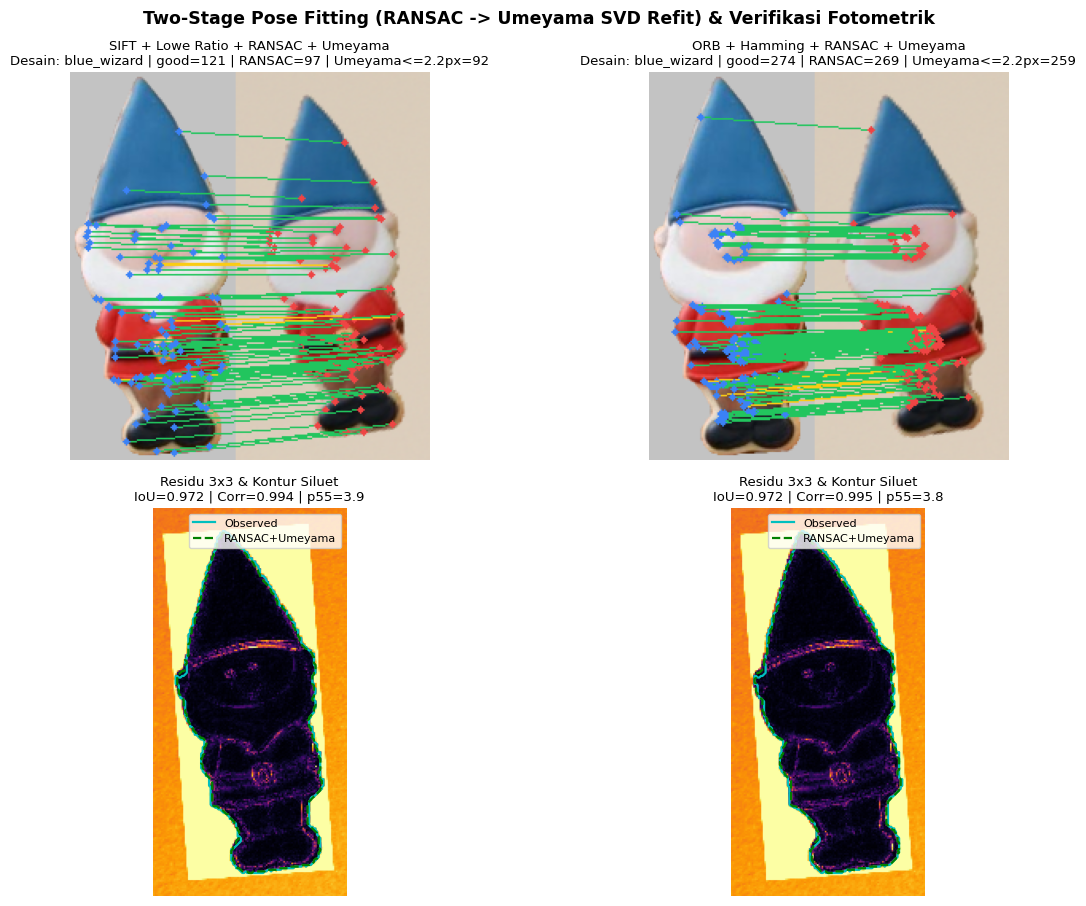

In [7]:
MODEL_BENCHMARKS = {
    "main_ncc": {
        "label": "Main Multi-Template NCC",
        "elapsed_train_s": float(elapsed_train),
        "sec_per_img": float(elapsed_train / len(df_pred)),
        "summary_df": pd.DataFrame(summary_rows),
        "pred_train_df": df_pred.copy(),
    }
}
HIDDEN_LB_DFS = {"main_ncc": df_hidden_main.copy()}


def evaluate_and_record_model(model_key: str, model_label: str, predict_fn) -> pd.DataFrame:
    """Mengevaluasi satu pipeline Non-DL pada 100 citra berlabel beserta MAE per sisi."""
    rows = []
    with zipfile.ZipFile(TRAIN_ZIP) as zf:
        t0 = time.time()
        for ann in annotations:
            img_id = Path(ann["image"]).stem
            with Image.open(io.BytesIO(zf.read(ann["image"]))) as im:
                rgb = np.asarray(im.convert("RGB"))
            pred = predict_fn(rgb, references, leaderboard=True)
            rows.append({"image_id": img_id, **pred})
        elapsed_s = time.time() - t0

    df_m = pd.DataFrame(rows, columns=cube_columns(True))
    validate_cube_predictions(df_m, df_truth.image_id.tolist(), len(references), leaderboard=True)

    sp_rows = []
    face_def_mae = {}
    for sp in ("train", "val", "test", "all"):
        if sp == "all":
            sub_p, sub_t = df_m, df_truth
        else:
            sub_t = df_truth[df_truth["split"] == sp]
            sub_p = df_m[df_m["image_id"].isin(set(sub_t["image_id"]))]
        m_main = evaluate_cube_dataframe(sub_p[cube_columns(False)], sub_t, leaderboard=False)
        m_lb = evaluate_cube_dataframe(sub_p, sub_t, leaderboard=True)
        if sp == "all":
            face_def_mae = {fn: m_main[f"mae_{fn}_defective"] for fn in FACES}
        sp_rows.append(
            {
                "split": sp,
                "n_cubes": len(sub_p),
                "MAE_total": m_main["mae_total"],
                "MAE_defective": m_main["mae_defective"],
                "MAE_design_count": m_lb["mae_design_count"],
                "ExactMatch_Face_%": m_main["exact_match_face_pct"],
                "ExactMatch_Image_Main_%": m_main["exact_match_image_pct"],
                "ExactMatch_Image_LB_%": m_lb["exact_match_image_pct"],
            }
        )

    sp_df = pd.DataFrame(sp_rows)
    MODEL_BENCHMARKS[model_key] = {
        "label": model_label,
        "elapsed_train_s": float(elapsed_s),
        "sec_per_img": float(elapsed_s / len(df_m)),
        "summary_df": sp_df,
        "face_def_mae": face_def_mae,
        "pred_train_df": df_m,
    }
    print(f"[{model_label}] 100 citra berlabel selesai dalam {elapsed_s:.2f}s ({elapsed_s / len(df_m):.3f}s/citra)")
    return sp_df


# Hitung juga MAE_defective per sisi untuk main_ncc
_m_main_all = evaluate_cube_dataframe(df_pred[cube_columns(False)], df_truth, leaderboard=False)
MODEL_BENCHMARKS["main_ncc"]["face_def_mae"] = {fn: _m_main_all[f"mae_{fn}_defective"] for fn in FACES}


def export_hidden_submission(model_key: str, predict_fn, out_prefix: str) -> pd.DataFrame:
    """Menjalankan inferensi 200 citra hidden lalu mengekspor CSV leaderboard & main tervalidasi."""
    lb_path = ROOT / "submissions" / f"{out_prefix}_lb.csv"
    main_path = ROOT / "submissions" / f"{out_prefix}_main.csv"

    rows = []
    with zipfile.ZipFile(HIDDEN_ZIP) as zf:
        t0 = time.time()
        for img_id in sample_ids:
            with Image.open(io.BytesIO(zf.read(path_map[img_id]))) as im:
                rgb = np.asarray(im.convert("RGB"))
            pred = predict_fn(rgb, references, leaderboard=True)
            rows.append({"image_id": img_id, **pred})
        elapsed_h = time.time() - t0

    df_lb = pd.DataFrame(rows, columns=cube_columns(True))
    df_main = df_lb[cube_columns(False)].copy()
    validate_cube_predictions(df_lb, sample_ids, len(references), leaderboard=True)
    validate_cube_predictions(df_main, sample_ids, len(references), leaderboard=False)

    lb_path.parent.mkdir(parents=True, exist_ok=True)
    df_lb.to_csv(lb_path, index=False)
    df_main.to_csv(main_path, index=False)
    HIDDEN_LB_DFS[model_key] = df_lb

    tot_def = df_lb[[f"{f}_defective" for f in FACES]].sum(axis=1)
    print(
        f"[{model_key}] Hidden 200 citra selesai dalam {elapsed_h:.2f}s ({elapsed_h / len(df_lb):.3f}s/citra) "
        f"-> {lb_path.name} & {main_path.name}"
    )
    print(f"  Distribusi cacat per kubus (0/1/2): {tot_def.value_counts().sort_index().to_dict()}")
    return df_lb


# Visualisasi Two-Stage RANSAC + Umeyama Refit + Residu Fotometrik (SIFT vs ORB) pada sampel sisi 'front'.
front_face = warped_faces["front"]
front_comps, front_cmed = segment_face_cookies(front_face)


def _solve_keypoint_vis_sample(roi_rgb, roi_solid, roi_raw, bw, bh, cmed, method):
    rc_feat = _prepare_feature_refs(references, method=method)
    det, matcher, r_thr, rp_thr, target_px = _build_feature_config(method)
    rh_o, rw_o = roi_rgb.shape[:2]
    roi_solid_bool = roi_solid > 0
    roi_raw_bool = roi_raw > 0
    roi_f = roi_rgb.astype(np.float32)
    up = float(np.clip(target_px / max(1.0, float(max(bw, bh))), 2.0, 3.6))
    up_w, up_h = int(round(rw_o * up)), int(round(rh_o * up))
    roi_up_gray = cv2.cvtColor(cv2.resize(roi_rgb, (up_w, up_h), interpolation=cv2.INTER_CUBIC), cv2.COLOR_RGB2GRAY)
    roi_up_mask = cv2.dilate(cv2.resize(roi_solid, (up_w, up_h), interpolation=cv2.INTER_NEAREST), np.ones((7, 7), np.uint8), iterations=1) * 255
    kps_obs, des_obs = det.detectAndCompute(roi_up_gray, roi_up_mask)
    if des_obs is None or len(kps_obs) < 4:
        return None
    obs_pts = np.float32([kp.pt for kp in kps_obs]) / up
    best_vis, best_sc = None, -1e9
    for did, re in rc_feat.items():
        if re["des"] is None or len(re["des"]) < 4:
            continue
        knn = matcher.knnMatch(re["des"], des_obs, k=2)
        good = [m for pair in knn if len(pair) == 2 for m, n in [pair] if m.distance < r_thr * n.distance]
        if len(good) < 4:
            continue
        src_p = np.float32([re["kps_pts"][m.queryIdx] for m in good])
        dst_p = np.float32([obs_pts[m.trainIdx] for m in good])
        M0, inl = cv2.estimateAffinePartial2D(
            src_p, dst_p, method=cv2.RANSAC, ransacReprojThreshold=rp_thr, maxIters=1200, confidence=0.995, refineIters=15
        )
        if M0 is None or inl is None or int(inl.sum()) < 4:
            continue
        sc_est = float(np.hypot(M0[0, 0], M0[0, 1]))
        if not (0.18 <= sc_est <= 0.90):
            continue
        errs0 = np.linalg.norm((src_p @ M0[:, :2].T) + M0[:, 2] - dst_p, axis=1)
        tight = errs0 <= 2.2
        M_fin = _umeyama_2d_similarity(src_p[tight], dst_p[tight]) if int(tight.sum()) >= 5 else None
        if M_fin is None:
            M_fin = M0
        inl_fin = np.linalg.norm((src_p @ M_fin[:, :2].T) + M_fin[:, 2] - dst_p, axis=1) <= rp_thr
        mw = cv2.warpAffine(re["mask"], M_fin, (rw_o, rh_o), flags=cv2.INTER_NEAREST, borderValue=0) > 0
        iou = float(np.sum(mw & roi_solid_bool)) / float(max(1, int(np.sum(mw | roi_solid_bool))))
        if iou < 0.35:
            continue
        tw = cv2.warpAffine(re["rgb"], M_fin, (rw_o, rh_o), flags=cv2.INTER_LINEAR, borderValue=tuple(float(v) for v in cmed))
        mw_er = cv2.erode(mw.astype(np.uint8), np.ones((3, 3), np.uint8), iterations=1) > 0
        intact = mw_er & roi_raw_bool
        corr, p55 = 0.0, 90.0
        rsh = np.zeros((rh_o, rw_o), dtype=np.float32)
        if int(intact.sum()) >= 60:
            gs, bs = _fit_shading_affine(roi_f[intact], tw[intact])
            nt = tw * gs + bs
            p55 = float(np.percentile(np.linalg.norm(roi_f[intact] - nt[intact], axis=1), 55))
            ov = roi_f[intact] - roi_f[intact].mean(axis=0, keepdims=True)
            tv = tw[intact] - tw[intact].mean(axis=0, keepdims=True)
            corr = float(np.sum(ov * tv) / (np.sqrt(np.sum(ov * ov) * np.sum(tv * tv)) + 1e-6))
            pnt = np.pad(nt, ((1, 1), (1, 1), (0, 0)), mode="edge")
            rsh.fill(1e6)
            for sy in range(3):
                for sx in range(3):
                    rsh = np.minimum(rsh, np.linalg.norm(roi_f - pnt[sy : sy + rh_o, sx : sx + rw_o], axis=2))
        sc_hyp = 0.60 * corr + 0.35 * iou + 0.22 * min(int(inl_fin.sum()), 35) / 35.0 - 0.010 * p55
        if sc_hyp > best_sc:
            best_sc = sc_hyp
            best_vis = (re, M_fin, inl_fin, tight, good, src_p, dst_p, iou, corr, p55, rsh, mw)
    return best_vis


sample_pack = None
for cand_c in front_comps:
    bx, by, bw, bh = cand_c["bbox"]
    pad = 14
    x0, y0 = max(0, bx - pad), max(0, by - pad)
    x1, y1 = min(front_face.shape[1], bx + bw + pad), min(front_face.shape[0], by + bh + pad)
    r_rgb = front_face[y0:y1, x0:x1]
    r_sol = cand_c["mask_solid"][y0:y1, x0:x1]
    r_raw = cand_c["mask_raw"][y0:y1, x0:x1]
    v_sift = _solve_keypoint_vis_sample(r_rgb, r_sol, r_raw, bw, bh, front_cmed, "sift")
    v_orb = _solve_keypoint_vis_sample(r_rgb, r_sol, r_raw, bw, bh, front_cmed, "orb")
    if v_sift is not None and v_orb is not None:
        sample_pack = (r_rgb, r_sol, {"sift": v_sift, "orb": v_orb})
        break

if sample_pack is None:
    for fn_alt in FACES:
        wf_alt = warped_faces[fn_alt]
        cs_alt, cm_alt = segment_face_cookies(wf_alt)
        for cand_c in cs_alt:
            bx, by, bw, bh = cand_c["bbox"]
            pad = 14
            x0, y0 = max(0, bx - pad), max(0, by - pad)
            x1, y1 = min(wf_alt.shape[1], bx + bw + pad), min(wf_alt.shape[0], by + bh + pad)
            r_rgb = wf_alt[y0:y1, x0:x1]
            r_sol = cand_c["mask_solid"][y0:y1, x0:x1]
            r_raw = cand_c["mask_raw"][y0:y1, x0:x1]
            v_sift = _solve_keypoint_vis_sample(r_rgb, r_sol, r_raw, bw, bh, cm_alt, "sift")
            v_orb = _solve_keypoint_vis_sample(r_rgb, r_sol, r_raw, bw, bh, cm_alt, "orb")
            if v_sift is not None and v_orb is not None:
                sample_pack = (r_rgb, r_sol, {"sift": v_sift, "orb": v_orb})
                break
        if sample_pack is not None:
            break

assert sample_pack is not None, "Sampel visualisasi keypoint SIFT & ORB tidak ditemukan."
roi_rgb, roi_solid, vis_by_method = sample_pack
rh_o, rw_o = roi_rgb.shape[:2]

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2))
for col_i, (method, title_lbl) in enumerate([("sift", "SIFT + Lowe Ratio + RANSAC + Umeyama"), ("orb", "ORB + Hamming + RANSAC + Umeyama")]):
    re_win, M_fin, inl_fin, tight_m, good_m, src_p, dst_p, iou, corr, p55, rsh, mw_b = vis_by_method[method]
    ref_u8 = np.clip(re_win["rgb"], 0, 255).astype(np.uint8)
    scale_panel = rh_o / float(ref_u8.shape[0])
    ref_disp = cv2.resize(ref_u8, (max(1, int(round(ref_u8.shape[1] * scale_panel))), rh_o), interpolation=cv2.INTER_AREA)
    canvas = np.ascontiguousarray(np.hstack([ref_disp, roi_rgb.copy()]))
    ox = ref_disp.shape[1]

    for f_inl, f_tight, p_ref, p_obs in zip(inl_fin, tight_m, src_p, dst_p):
        if f_inl:
            pt1 = (int(round(p_ref[0] * scale_panel)), int(round(p_ref[1] * scale_panel)))
            pt2 = (int(round(p_obs[0] + ox)), int(round(p_obs[1])))
            line_col = (34, 197, 94) if f_tight else (250, 204, 21)
            cv2.line(canvas, pt1, pt2, line_col, 1)
            cv2.circle(canvas, pt1, 2, (59, 130, 246), -1)
            cv2.circle(canvas, pt2, 2, (239, 68, 68), -1)

    axes[0, col_i].imshow(canvas)
    axes[0, col_i].set_title(
        f"{title_lbl}\nDesain: {re_win['name']} | good={len(good_m)} | RANSAC={int(inl_fin.sum())} | Umeyama<=2.2px={int(tight_m.sum())}",
        fontsize=9.5,
    )

    axes[1, col_i].imshow(rsh, cmap="inferno", vmin=0, vmax=50)
    cnt_obs, _ = cv2.findContours(roi_solid.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnt_wrp, _ = cv2.findContours(mw_b.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for ci_o, c_o in enumerate(cnt_obs):
        pts_o = c_o.reshape(-1, 2)
        axes[1, col_i].plot(np.r_[pts_o[:, 0], pts_o[0, 0]], np.r_[pts_o[:, 1], pts_o[0, 1]], "c-", lw=1.6, label="Observed" if ci_o == 0 else None)
    for ci_w, c_w in enumerate(cnt_wrp):
        pts_w = c_w.reshape(-1, 2)
        axes[1, col_i].plot(np.r_[pts_w[:, 0], pts_w[0, 0]], np.r_[pts_w[:, 1], pts_w[0, 1]], "g--", lw=1.6, label="RANSAC+Umeyama" if ci_w == 0 else None)
    axes[1, col_i].set_title(f"Residu 3x3 & Kontur Siluet\nIoU={iou:.3f} | Corr={corr:.3f} | p55={p55:.1f}", fontsize=9.5)
    axes[1, col_i].legend(loc="upper right", fontsize=8, framealpha=0.8)

for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Two-Stage Pose Fitting (RANSAC -> Umeyama SVD Refit) & Verifikasi Fotometrik", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.show()

### 7. Model Tambahan 1 — SIFT + Lowe Ratio Test + RANSAC & Umeyama Refit
Pada model pertama, kami mengekstraksi deskriptor float 128-dimensi SIFT (`nfeatures=850`, `contrastThreshold=0.012`, `edgeThreshold=16`) dari ROI yang diskalakan adaptif (`target 380 px`, `2.0x–3.6x`) dan menyaring pasangan `NORM_L2` memakai Lowe ratio test (`0.82`). Setelah RANSAC awal (`reproj=4.8 px`), kami melakukan *refit* analitik 4-DOF via SVD Umeyama pada *tight inliers* ($e \le 2.2\text{ px}$), memverifikasi 3 kandidat teratas secara fotometrik ($\text{corr},\ \text{IoU},\ p_{55}$), mengevaluasi residu toleran-geser `3x3` (dengan fallback `Contour + HSV` jika inlier lemah), lalu mengekspor hasilnya ke `task2_sift_lb.csv` dan `task2_sift_main.csv`.

In [8]:
df_sift_eval = evaluate_and_record_model("sift_ransac", "SIFT + RANSAC", predict_cube_sift_ransac)
display(df_sift_eval)

df_hidden_sift = export_hidden_submission(
    "sift_ransac", predict_cube_sift_ransac, "task2_sift"
)
display(df_hidden_sift.head(5))

[SIFT + RANSAC] 100 citra berlabel selesai dalam 108.61s (1.086s/citra)


,split,n_cubes,MAE_total,MAE_defective,MAE_design_count,ExactMatch_Face_%,ExactMatch_Image_Main_%,ExactMatch_Image_LB_%
0,train,70,0.0,0.004762,0.004762,99.523810,98.571429,97.142857
1,val,15,0.0,0.000000,0.000000,100.000000,100.000000,100.000000
2,test,15,0.0,0.000000,0.000000,100.000000,100.000000,100.000000
3,all,100,0.0,0.003333,0.003333,99.666667,99.000000,98.000000


[sift_ransac] Hidden 200 citra selesai dalam 231.20s (1.156s/citra) -> task2_sift_lb.csv & task2_sift_main.csv
  Distribusi cacat per kubus (0/1/2): {0: 43, 1: 75, 2: 82}


,image_id,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_043c007cea1e1da0,1,2,3,0,1,1,1,2,2
1,cube_05d5a08c09734e6e,1,3,1,0,1,0,1,1,1
2,cube_0817258b17ffb7d2,2,1,3,0,0,2,2,1,3
3,cube_0a759e86474d3700,1,1,1,0,0,0,1,1,1
4,cube_0ad969fcad819b22,2,3,2,0,0,0,2,2,2


### 8. Model Tambahan 2 — ORB Binary Descriptor + Hamming Matcher + RANSAC & Umeyama Refit
Pada model kedua, kami mengekstraksi fitur biner FAST+BRIEF melalui `cv2.ORB_create` (`nfeatures=950`, `fastThreshold=5`, `scaleFactor=1.12`, `nlevels=10`) pada ROI adaptif (`target 320 px`) lalu mencocokkannya memakai jarak bitwise `NORM_HAMMING` dan Lowe ratio (`0.82`). Alur RANSAC (`reproj=4.2 px`), *refit* Umeyama SVD, verifikasi fotometrik top-3, serta penilaian cacat toleran-geser `3x3` tetap konsisten untuk menghasilkan `task2_orb_lb.csv` dan `task2_orb_main.csv`.

In [9]:
df_orb_eval = evaluate_and_record_model("orb_ransac", "ORB + RANSAC", predict_cube_orb_ransac)
display(df_orb_eval)

df_hidden_orb = export_hidden_submission(
    "orb_ransac", predict_cube_orb_ransac, "task2_orb"
)
display(df_hidden_orb.head(5))

[ORB + RANSAC] 100 citra berlabel selesai dalam 80.17s (0.802s/citra)


,split,n_cubes,MAE_total,MAE_defective,MAE_design_count,ExactMatch_Face_%,ExactMatch_Image_Main_%,ExactMatch_Image_LB_%
0,train,70,0.0,0.014286,0.000000,99.047619,97.142857,97.142857
1,val,15,0.0,0.022222,0.000000,97.777778,93.333333,93.333333
2,test,15,0.0,0.000000,0.022222,100.000000,100.000000,93.333333
3,all,100,0.0,0.013333,0.003333,99.000000,97.000000,96.000000


[orb_ransac] Hidden 200 citra selesai dalam 154.28s (0.771s/citra) -> task2_orb_lb.csv & task2_orb_main.csv
  Distribusi cacat per kubus (0/1/2): {0: 44, 1: 73, 2: 83}


,image_id,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_043c007cea1e1da0,1,2,3,0,1,1,1,2,2
1,cube_05d5a08c09734e6e,1,3,1,0,1,0,1,1,1
2,cube_0817258b17ffb7d2,2,1,3,0,0,2,2,1,3
3,cube_0a759e86474d3700,1,1,1,0,0,0,1,1,1
4,cube_0ad969fcad819b22,2,3,2,0,0,0,2,2,2


### 9. Model Tambahan 3 — Kontur Terorientasi, Profil Lebar 6-Strip, & Histogram HSV V-Ternormalisasi
Sebagai baseline bebas-keypoint dan bebas-NCC, kami meluruskan cookie mengikuti sumbu utama momen kontur ($\theta = \frac{1}{2}\arctan2(2\mu_{11}, \mu_{20}-\mu_{02})$), menormalisasi median kanal `V`, lalu mengekstrak vektor HSV `[H, S]` (`16x6`) + `[V]` (`8`) global, 3 zona vertikal, serta profil 6-strip beserta lebar siluetnya (`widths`). Untuk menangani potongan tepi (`boundary_cut`), kami menerapkan *trimmed mean* 6-strip serta pencocokan *dual-anchor* atas/bawah saat rasio aspek menyusut (`ar < 0.88 * ref_ar`), lalu mengekspor prediksi ke `task2_contour_lb.csv` dan `task2_contour_main.csv`.

[Contour + HSV] 100 citra berlabel selesai dalam 31.44s (0.314s/citra)


,split,n_cubes,MAE_total,MAE_defective,MAE_design_count,ExactMatch_Face_%,ExactMatch_Image_Main_%,ExactMatch_Image_LB_%
0,train,70,0.0,0.038095,0.028571,96.190476,88.571429,80.000000
1,val,15,0.0,0.066667,0.022222,93.333333,80.000000,73.333333
2,test,15,0.0,0.000000,0.022222,100.000000,100.000000,93.333333
3,all,100,0.0,0.036667,0.026667,96.333333,89.000000,81.000000


[contour_hsv] Hidden 200 citra selesai dalam 77.71s (0.389s/citra) -> task2_contour_lb.csv & task2_contour_main.csv
  Distribusi cacat per kubus (0/1/2): {0: 42, 1: 68, 2: 90}


,image_id,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_043c007cea1e1da0,1,2,3,0,1,1,1,2,2
1,cube_05d5a08c09734e6e,1,3,1,0,1,0,1,1,1
2,cube_0817258b17ffb7d2,2,1,3,0,0,2,2,1,3
3,cube_0a759e86474d3700,1,1,1,0,1,0,1,1,1
4,cube_0ad969fcad819b22,2,3,2,0,1,0,2,2,2


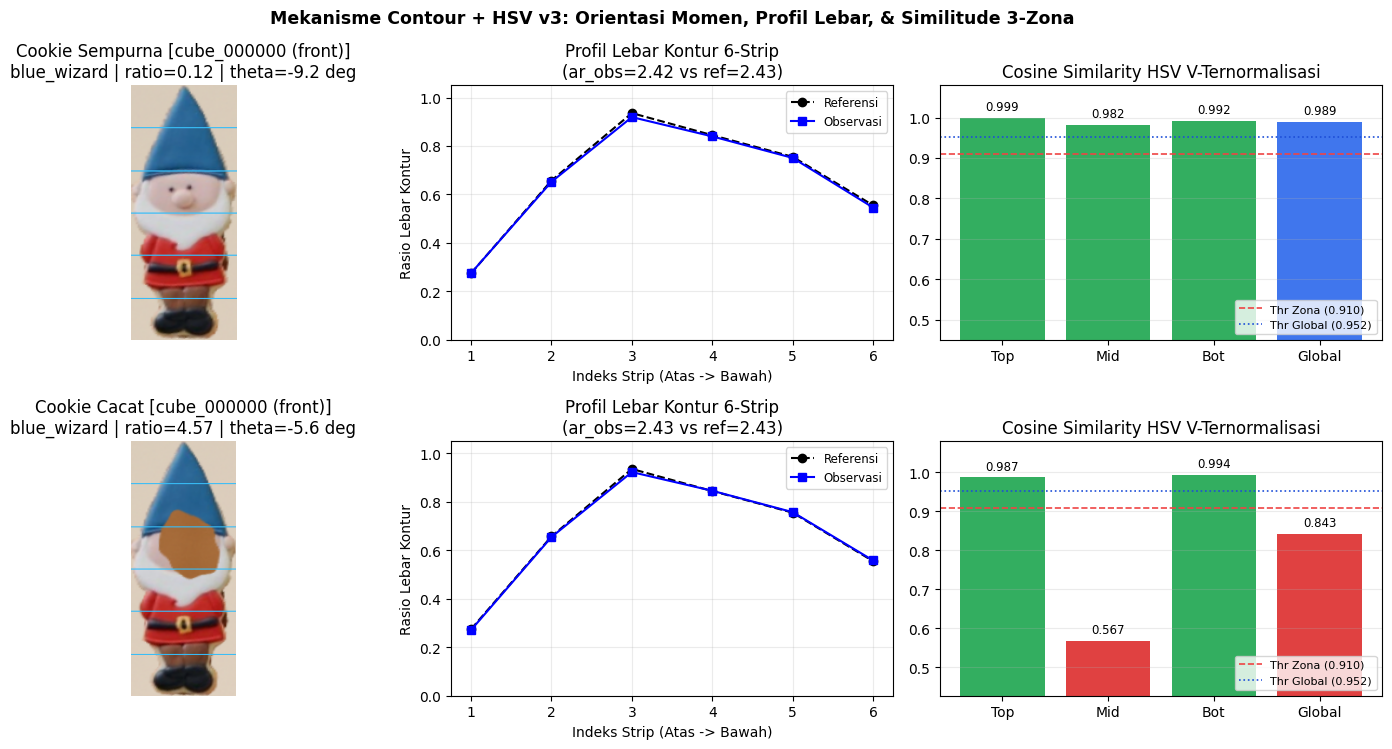

In [10]:
df_chsv_eval = evaluate_and_record_model("contour_hsv", "Contour + HSV", predict_cube_contour_hsv)
display(df_chsv_eval)

df_hidden_chsv = export_hidden_submission(
    "contour_hsv", predict_cube_contour_hsv, "task2_contour"
)
display(df_hidden_chsv.head(5))

# Visualisasi mekanisme matematis Contour + HSV v3: Sempurna vs Cacat nyata pada sisi kubus.
chsv_refs = _prepare_contour_hsv_refs(references)
chsv_pair = {}
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    for ann_v in annotations[:60]:
        with Image.open(io.BytesIO(zf.read(ann_v["image"]))) as im:
            rgb_v = np.asarray(im.convert("RGB"))
        _, dm_v = fit_background_model(rgb_v)
        hx_v, _ = extract_cube_hexagon(rgb_v, dist_map=dm_v)
        vc_v, par_v = compute_vanishing_center(hx_v, rgb=rgb_v)
        fq_v = segment_cube_faces(rgb_v, hx_v, vc_v, parity=par_v)
        for fn_v in FACES:
            wf_v, _ = rectify_face(rgb_v, fq_v[fn_v], CANONICAL_FACE_SIZE)
            cs_v, cm_v = segment_face_cookies(wf_v)
            for c_v in cs_v:
                sc_c = _score_contour_hsv_cookie(wf_v, c_v, chsv_refs, cm_v)
                if not sc_c["is_defective"] and sc_c["defect_ratio"] < 0.70 and "sempurna" not in chsv_pair:
                    chsv_pair["sempurna"] = (wf_v, c_v, cm_v, sc_c, f"{Path(ann_v['image']).stem} ({fn_v})")
                elif sc_c["is_defective"] and "cacat" not in chsv_pair:
                    chsv_pair["cacat"] = (wf_v, c_v, cm_v, sc_c, f"{Path(ann_v['image']).stem} ({fn_v})")
        if len(chsv_pair) == 2:
            break

assert len(chsv_pair) == 2, f"Pasangan sampel Contour+HSV tidak lengkap: {list(chsv_pair)}"

fig, axes = plt.subplots(2, 3, figsize=(14.5, 7.6))
for row_i, (k_c, label_tag) in enumerate([("sempurna", "Cookie Sempurna"), ("cacat", "Cookie Cacat")]):
    wf_c, c_item, c_med, sc_c, tag_c = chsv_pair[k_c]
    th_c, ar_c = _major_axis_angle_deg(c_item["mask_solid"])
    cand_c = [th_c, th_c + 180.0] + ([0.0, 90.0, 180.0, -90.0] if ar_c < 1.48 else [])
    best_obs_st, best_ref_st, best_rc_c, best_sc_c = None, chsv_refs[sc_c["design_id"]], None, -1e9
    for ang_c in cand_c:
        rc_c = _rotate_crop_patch(wf_c, c_item, ang_c, c_med)
        if rc_c is None:
            continue
        st_o = _extract_contour_zone_stats(rc_c[0], rc_c[1], rc_c[2], n_strips=6)
        s6 = [float(np.dot(a, b)) for a, b in zip(st_o["strips"], best_ref_st["strips"])]
        wp = float(np.mean(np.abs(st_o["widths"] - best_ref_st["widths"])))
        sc_tot = 0.25 * float(np.dot(st_o["g_hist"], best_ref_st["g_hist"])) + 0.75 * (sum(sorted(s6)[1:]) / 5.0 - 0.18 * wp)
        if sc_tot > best_sc_c:
            best_sc_c = sc_tot
            best_obs_st, best_rc_c = st_o, rc_c

    rot_img_c, rot_sol_c, _, _ = best_rc_c
    ys_c, xs_c = np.where(rot_sol_c > 0)
    crop_vis = np.ascontiguousarray(
        np.clip(rot_img_c[int(ys_c.min()):int(ys_c.max()) + 1, int(xs_c.min()):int(xs_c.max()) + 1], 0, 255),
        dtype=np.uint8,
    )
    bh_c, bw_c = crop_vis.shape[:2]
    for s_i in range(1, 6):
        y_line = int(round(s_i * bh_c / 6.0))
        cv2.line(crop_vis, (0, y_line), (bw_c - 1, y_line), (56, 189, 248), 1)
    axes[row_i, 0].imshow(crop_vis)
    axes[row_i, 0].set_title(f"{label_tag} [{tag_c}]\n{best_ref_st['name']} | ratio={sc_c['defect_ratio']:.2f} | theta={th_c:.1f} deg")
    axes[row_i, 0].axis("off")

    strips_x = np.arange(1, 7)
    axes[row_i, 1].plot(strips_x, best_ref_st["widths"], "k--o", label="Referensi")
    axes[row_i, 1].plot(strips_x, best_obs_st["widths"], "b-s", label="Observasi")
    axes[row_i, 1].set_xticks(strips_x)
    axes[row_i, 1].set_ylim(0.0, 1.05)
    axes[row_i, 1].set_xlabel("Indeks Strip (Atas -> Bawah)")
    axes[row_i, 1].set_ylabel("Rasio Lebar Kontur")
    axes[row_i, 1].set_title(f"Profil Lebar Kontur 6-Strip\n(ar_obs={best_obs_st['ar']:.2f} vs ref={best_ref_st['ar']:.2f})")
    axes[row_i, 1].legend(fontsize=8.5)
    axes[row_i, 1].grid(alpha=0.25)

    z_labels = ["Top", "Mid", "Bot", "Global"]
    z_vals = [float(np.dot(a, b)) for a, b in zip(best_obs_st["z3"], best_ref_st["z3"])] + [float(np.dot(best_obs_st["g_hist"], best_ref_st["g_hist"]))]
    bar_cols = ["#dc2626" if v < 0.91 else "#16a34a" for v in z_vals[:3]] + ["#dc2626" if z_vals[3] < 0.952 else "#2563eb"]
    axes[row_i, 2].bar(z_labels, z_vals, color=bar_cols, alpha=0.88)
    axes[row_i, 2].axhline(0.910, color="#ef4444", ls="--", lw=1.2, label="Thr Zona (0.910)")
    axes[row_i, 2].axhline(0.952, color="#1d4ed8", ls=":", lw=1.2, label="Thr Global (0.952)")
    axes[row_i, 2].set_ylim(min(0.45, max(0.0, min(z_vals) - 0.14)), 1.08)
    for bi, bv in enumerate(z_vals):
        axes[row_i, 2].text(bi, bv + 0.012, f"{bv:.3f}", ha="center", va="bottom", fontsize=8.5)
    axes[row_i, 2].set_title("Cosine Similarity HSV V-Ternormalisasi")
    axes[row_i, 2].legend(loc="lower right", fontsize=8)
    axes[row_i, 2].grid(axis="y", alpha=0.25)

plt.suptitle("Mekanisme Contour + HSV v3: Orientasi Momen, Profil Lebar, & Similitude 3-Zona", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.show()

### 10. Perbandingan Lintas Model, Heatmap Error per Sisi, & Audit CSV Submisi
Terakhir, kami merangkum kinerja keempat pendekatan Non-Deep Learning pada split `all` (`100` kubus) dan `test` (`15` kubus), memetakan distribusi `MAE_defective` pada sisi `front`, `right`, dan `top`, serta mengaudit kedelapan berkas CSV di `submissions/` untuk memverifikasi validitas skema dan keunikan prediksi antarmodel.

=== Perbandingan Kinerja pada Seluruh 100 Citra Berlabel (split='all') ===


,Model,sec/citra,MAE_total,MAE_defective,MAE_design_count,ExactMatch_Face_%,ExactMatch_Main_%,ExactMatch_LB_%
0,Main Multi-Template NCC,4.601,0.0,0.000000,0.000000,100.000000,100.0,100.0
1,SIFT + RANSAC,1.086,0.0,0.003333,0.003333,99.666667,99.0,98.0
2,ORB + RANSAC,0.802,0.0,0.013333,0.003333,99.000000,97.0,96.0
3,Contour + HSV,0.314,0.0,0.036667,0.026667,96.333333,89.0,81.0


=== Perbandingan Kinerja pada Split Uji (split='test', n=15) ===


,Model,sec/citra,MAE_total,MAE_defective,MAE_design_count,ExactMatch_Face_%,ExactMatch_Main_%,ExactMatch_LB_%
0,Main Multi-Template NCC,4.601,0.0,0.0,0.000000,100.0,100.0,100.000000
1,SIFT + RANSAC,1.086,0.0,0.0,0.000000,100.0,100.0,100.000000
2,ORB + RANSAC,0.802,0.0,0.0,0.022222,100.0,100.0,93.333333
3,Contour + HSV,0.314,0.0,0.0,0.022222,100.0,100.0,93.333333


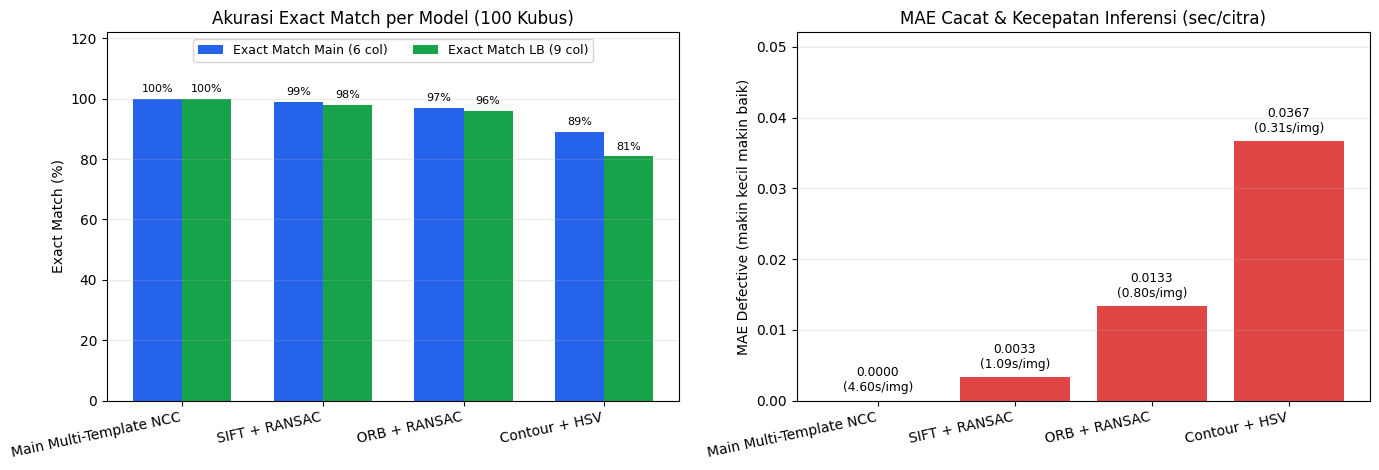

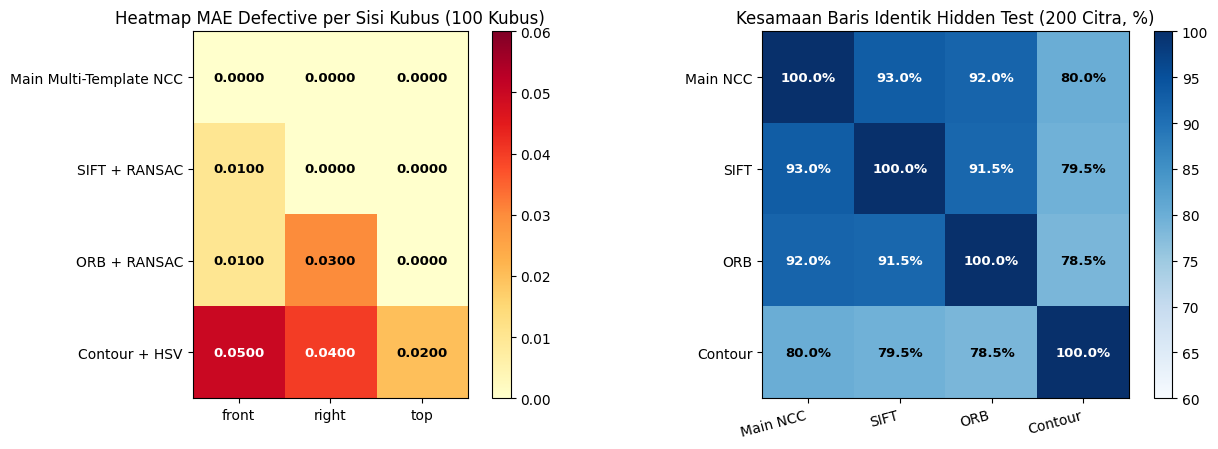


=== Audit Berkas CSV Submisi di submissions/ ===


,model_key,jenis,file,rows,cols,sha256_12,valid
0,main_ncc,leaderboard (10 col),task2_ncc_lb.csv,200,10,a5de17a7ef9a,True
1,main_ncc,main (7 col),task2_ncc_main.csv,200,7,03a4f0239c59,True
2,sift_ransac,leaderboard (10 col),task2_sift_lb.csv,200,10,8fe96d25bb75,True
3,sift_ransac,main (7 col),task2_sift_main.csv,200,7,f9f90c233588,True
4,orb_ransac,leaderboard (10 col),task2_orb_lb.csv,200,10,70f928c5b87e,True
5,orb_ransac,main (7 col),task2_orb_main.csv,200,7,95b6c0fba490,True
6,contour_hsv,leaderboard (10 col),task2_contour_lb.csv,200,10,093b5ec57efa,True
7,contour_hsv,main (7 col),task2_contour_main.csv,200,7,d6d10dd2fd12,True


=== Persentase Kesamaan Baris Identik Antar-Submisi Hidden (200 Citra) ===


,main_ncc,sift_ransac,orb_ransac,contour_hsv
main_ncc,100.0,93.0,92.0,80.0
sift_ransac,93.0,100.0,91.5,79.5
orb_ransac,92.0,91.5,100.0,78.5
contour_hsv,80.0,79.5,78.5,100.0


In [11]:
def build_comparison_table(split_name: str) -> pd.DataFrame:
    comp_rows = []
    for key in ("main_ncc", "sift_ransac", "orb_ransac", "contour_hsv"):
        entry = MODEL_BENCHMARKS[key]
        row_sp = entry["summary_df"].loc[entry["summary_df"]["split"] == split_name].iloc[0].to_dict()
        comp_rows.append(
            {
                "Model": entry["label"],
                "sec/citra": round(entry["sec_per_img"], 3),
                "MAE_total": row_sp["MAE_total"],
                "MAE_defective": row_sp["MAE_defective"],
                "MAE_design_count": row_sp["MAE_design_count"],
                "ExactMatch_Face_%": row_sp["ExactMatch_Face_%"],
                "ExactMatch_Main_%": row_sp["ExactMatch_Image_Main_%"],
                "ExactMatch_LB_%": row_sp["ExactMatch_Image_LB_%"],
            }
        )
    return pd.DataFrame(comp_rows)


df_cmp_all = build_comparison_table("all")
df_cmp_test = build_comparison_table("test")
print("=== Perbandingan Kinerja pada Seluruh 100 Citra Berlabel (split='all') ===")
display(df_cmp_all)
print("=== Perbandingan Kinerja pada Split Uji (split='test', n=15) ===")
display(df_cmp_test)

# Figur 1: Exact Match (%) & MAE Defective vs Kecepatan
fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.8))
x_pos = np.arange(len(df_cmp_all))
w_bar = 0.35
b1 = axes[0].bar(x_pos - w_bar / 2, df_cmp_all["ExactMatch_Main_%"], w_bar, label="Exact Match Main (6 col)", color="#2563eb")
b2 = axes[0].bar(x_pos + w_bar / 2, df_cmp_all["ExactMatch_LB_%"], w_bar, label="Exact Match LB (9 col)", color="#16a34a")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(df_cmp_all["Model"], rotation=12, ha="right")
axes[0].set_ylim(0, 122)
axes[0].set_ylabel("Exact Match (%)")
axes[0].set_title("Akurasi Exact Match per Model (100 Kubus)")
axes[0].legend(loc="upper center", ncol=2, frameon=True, fontsize=9)
axes[0].grid(axis="y", alpha=0.25)
for rect in list(b1) + list(b2):
    h_val = rect.get_height()
    axes[0].text(rect.get_x() + rect.get_width() / 2, h_val + 1.5, f"{h_val:.0f}%", ha="center", va="bottom", fontsize=8)

axes[1].bar(x_pos, df_cmp_all["MAE_defective"], color="#dc2626", alpha=0.85)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(df_cmp_all["Model"], rotation=12, ha="right")
axes[1].set_ylabel("MAE Defective (makin kecil makin baik)")
axes[1].set_title("MAE Cacat & Kecepatan Inferensi (sec/citra)")
axes[1].grid(axis="y", alpha=0.25)
max_mae_def = max(0.01, float(df_cmp_all["MAE_defective"].max()))
for xi, (mae_v, spd_v) in enumerate(zip(df_cmp_all["MAE_defective"], df_cmp_all["sec/citra"])):
    axes[1].text(xi, mae_v + 0.025 * max_mae_def, f"{mae_v:.4f}\n({spd_v:.2f}s/img)", ha="center", va="bottom", fontsize=8.8)
axes[1].set_ylim(0, max_mae_def * 1.42)
plt.tight_layout()
plt.show()

# Figur 2: Heatmap MAE_defective per Sisi & Matriks Kesamaan Hidden (200 Citra)
lb_keys = ["main_ncc", "sift_ransac", "orb_ransac", "contour_hsv"]
lb_labels = [MODEL_BENCHMARKS[k]["label"] for k in lb_keys]
face_err_mat = np.array([[MODEL_BENCHMARKS[k]["face_def_mae"][fn] for fn in FACES] for k in lb_keys], dtype=float)

agree_mat = pd.DataFrame(index=lb_keys, columns=lb_keys, dtype=float)
for k1 in lb_keys:
    for k2 in lb_keys:
        eq_rows = (HIDDEN_LB_DFS[k1].iloc[:, 1:].to_numpy() == HIDDEN_LB_DFS[k2].iloc[:, 1:].to_numpy()).all(axis=1)
        agree_mat.loc[k1, k2] = round(float(eq_rows.mean() * 100.0), 1)

fig2, ax2 = plt.subplots(1, 2, figsize=(13.5, 4.6))
im0 = ax2[0].imshow(face_err_mat, cmap="YlOrRd", vmin=0.0, vmax=max(0.06, float(face_err_mat.max())))
ax2[0].set_xticks(range(len(FACES)))
ax2[0].set_xticklabels(FACES)
ax2[0].set_yticks(range(len(lb_labels)))
ax2[0].set_yticklabels(lb_labels)
ax2[0].set_title("Heatmap MAE Defective per Sisi Kubus (100 Kubus)")
for ri in range(face_err_mat.shape[0]):
    for ci in range(face_err_mat.shape[1]):
        val = face_err_mat[ri, ci]
        ax2[0].text(ci, ri, f"{val:.4f}", ha="center", va="center", color="white" if val > 0.03 else "black", fontsize=9.5, fontweight="bold")
plt.colorbar(im0, ax=ax2[0], fraction=0.046, pad=0.04)

ag_arr = agree_mat.to_numpy(dtype=float)
im1 = ax2[1].imshow(ag_arr, cmap="Blues", vmin=60.0, vmax=100.0)
ax2[1].set_xticks(range(len(lb_keys)))
ax2[1].set_xticklabels(["Main NCC", "SIFT", "ORB", "Contour"], rotation=15, ha="right")
ax2[1].set_yticks(range(len(lb_keys)))
ax2[1].set_yticklabels(["Main NCC", "SIFT", "ORB", "Contour"])
ax2[1].set_title("Kesamaan Baris Identik Hidden Test (200 Citra, %)")
for ri in range(ag_arr.shape[0]):
    for ci in range(ag_arr.shape[1]):
        val = ag_arr[ri, ci]
        ax2[1].text(ci, ri, f"{val:.1f}%", ha="center", va="center", color="white" if val > 85.0 else "black", fontsize=9.5, fontweight="bold")
plt.colorbar(im1, ax=ax2[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

submission_specs = [
    ("main_ncc", "task2_ncc_lb.csv", True),
    ("main_ncc", "task2_ncc_main.csv", False),
    ("sift_ransac", "task2_sift_lb.csv", True),
    ("sift_ransac", "task2_sift_main.csv", False),
    ("orb_ransac", "task2_orb_lb.csv", True),
    ("orb_ransac", "task2_orb_main.csv", False),
    ("contour_hsv", "task2_contour_lb.csv", True),
    ("contour_hsv", "task2_contour_main.csv", False),
]

audit_rows = []
for m_key, fname, is_lb in submission_specs:
    fpath = ROOT / "submissions" / fname
    df_chk = pd.read_csv(fpath, dtype={"image_id": str})
    validate_cube_predictions(df_chk, sample_ids, len(references), leaderboard=is_lb)
    sha12 = hashlib.sha256(fpath.read_bytes()).hexdigest()[:12]
    audit_rows.append(
        {
            "model_key": m_key,
            "jenis": "leaderboard (10 col)" if is_lb else "main (7 col)",
            "file": fname,
            "rows": len(df_chk),
            "cols": df_chk.shape[1],
            "sha256_12": sha12,
            "valid": True,
        }
    )

print("\n=== Audit Berkas CSV Submisi di submissions/ ===")
display(pd.DataFrame(audit_rows))
print("=== Persentase Kesamaan Baris Identik Antar-Submisi Hidden (200 Citra) ===")
display(agree_mat)

### 11. Daftar Referensi

Bradski, G. (2000). The OpenCV library. *Dr. Dobb's Journal*, *25*(11), 120–125.

Fischler, M. A., & Bolles, R. C. (1981). Random sample consensus: A paradigm for model fitting with applications to image analysis and automated cartography. *Communications of the ACM*, *24*(6), 381–395. https://doi.org/10.1145/358669.358692

Gonzalez, R. C., & Woods, R. E. (2018). *Digital image processing* (4th ed.). Pearson.

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, *585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Hartley, R., & Zisserman, A. (2004). *Multiple view geometry in computer vision* (2nd ed.). Cambridge University Press.

Hu, M.-K. (1962). Visual pattern recognition by moment invariants. *IRE Transactions on Information Theory*, *8*(2), 179–187. https://doi.org/10.1109/TIT.1962.1057692

Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics*, *35*(1), 73–101. https://doi.org/10.1214/aoms/1177703732

Lewis, J. P. (1995). Fast template matching. In *Proceedings of Vision Interface '95* (pp. 120–123). Canadian Image Processing and Pattern Recognition Society.

Lowe, D. G. (2004). Distinctive image features from scale-invariant keypoints. *International Journal of Computer Vision*, *60*(2), 91–110. https://doi.org/10.1023/B:VISI.0000029664.99615.94

OpenCV Team. (2026). *OpenCV 4.x documentation: Camera calibration and 3D reconstruction (`calib3d`), 2D features framework (`features2d`), and image processing (`imgproc`)*. https://docs.opencv.org/4.x/

Rahadianti, L., & Rachmadi, M. F. (2026). *Basic image processing 1 – Spatial domain* [Slide perkuliahan]. CSCE604133 Computer Vision, Fakultas Ilmu Komputer, Universitas Indonesia.

Rahadianti, L., & Rachmadi, M. F. (2026). *Basic image processing 2 – Frequency domain* [Slide perkuliahan]. CSCE604133 Computer Vision, Fakultas Ilmu Komputer, Universitas Indonesia.

Rahadianti, L., & Rachmadi, M. F. (2026). *Feature matching, recognition (object detection) and registration* [Slide perkuliahan]. CSCE604133 Computer Vision, Fakultas Ilmu Komputer, Universitas Indonesia.

Rahadianti, L., & Rachmadi, M. F. (2026). *Image features and recognition (classification)* [Slide perkuliahan]. CSCE604133 Computer Vision, Fakultas Ilmu Komputer, Universitas Indonesia.

Rahadianti, L., & Rachmadi, M. F. (2026). *Image segmentation and morphology* [Slide perkuliahan]. CSCE604133 Computer Vision, Fakultas Ilmu Komputer, Universitas Indonesia.

Rublee, E., Rabaud, V., Konolige, K., & Bradski, G. (2011). ORB: An efficient alternative to SIFT or SURF. In *2011 International Conference on Computer Vision (ICCV)* (pp. 2564–2571). IEEE. https://doi.org/10.1109/ICCV.2011.6126544

Szeliski, R. (2022). *Computer vision: Algorithms and applications* (2nd ed.). Springer. https://doi.org/10.1007/978-3-030-34372-9

Umeyama, S. (1991). Least-squares estimation of transformation parameters between two point patterns. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, *13*(4), 376–380. https://doi.org/10.1109/34.88573